In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('../data/processed/data_symbol.csv')
df.index = df['Unnamed: 0']
df.index.name = 'ID'
df = df.drop(columns=['Unnamed: 0'])

In [3]:
df.head()

,OR2T6,DKFZp686D0972,NOTCH2NL,SPIRE1,HSP90AA5P,SEMA4C,LOC728217,PTK7,RAC3,EEF2K,...,SLC7A4,XIST,ABCB8,SLC4A5,ABCA6,CYP8B1,SLC6A13,NAT1,ABCC1,UBC
ID,,,,,,,,,,,,,,,,,,,,,
GSM1423780,0.031249,0.074265,0.252653,0.070166,-0.175990,0.048764,-0.009946,0.054477,-0.079832,0.036474,...,-0.050536,0.378551,-0.033335,-0.029184,-0.088403,-0.005318,-0.081350,0.104146,-0.068883,0.170841
GSM1423781,0.047474,-0.012425,0.018820,0.081982,-0.125693,0.121229,-0.136300,0.121011,0.053280,0.039189,...,0.025661,-1.773067,-0.029328,-0.087389,-0.077986,0.045702,0.031939,-0.010796,-0.072794,0.154764
GSM1423782,0.025229,0.032135,-0.099547,0.086942,0.064224,0.020113,0.054568,0.000783,0.009715,-0.023340,...,0.083952,-1.871089,-0.000676,-0.175118,-0.172610,0.048495,-0.033006,-0.031901,-0.003799,0.359424
GSM1423783,0.077798,0.039638,0.139135,0.048914,-0.135775,0.013053,-0.117995,0.204031,0.195881,0.113818,...,-0.128077,0.338872,0.026046,0.066593,0.127126,0.086333,-0.016658,-0.027000,-0.046252,0.203776
GSM1423784,0.083566,-0.144225,0.159344,0.142559,0.021567,0.101992,-0.070392,-0.109156,-0.128335,0.058792,...,-0.024543,0.432422,0.019393,-0.145825,0.006903,0.048858,-0.128627,-0.036706,0.010318,0.153241


In [4]:
df.isna().sum().sum()

np.int64(282)

In [5]:
df = df.fillna(df.median())
df.isna().sum().sum()

np.int64(0)

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)
df_scaled = pd.DataFrame(df_scaled, index=df.index, columns=df.columns)

In [7]:
df_scaled.head()

,OR2T6,DKFZp686D0972,NOTCH2NL,SPIRE1,HSP90AA5P,SEMA4C,LOC728217,PTK7,RAC3,EEF2K,...,SLC7A4,XIST,ABCB8,SLC4A5,ABCA6,CYP8B1,SLC6A13,NAT1,ABCC1,UBC
ID,,,,,,,,,,,,,,,,,,,,,
GSM1423780,0.254365,0.832234,1.079151,-0.410539,-0.478512,-0.356403,0.739981,0.044569,-0.898983,0.170114,...,-0.271681,1.156761,-0.514035,-0.193177,-0.012643,-0.602730,-1.151849,1.130041,-0.525909,0.403159
GSM1423781,0.604992,0.181555,-0.373767,-0.344271,-0.187986,0.056659,-0.237621,0.632160,-0.036123,0.188472,...,0.433817,-0.926920,-0.475769,-0.907735,0.045136,0.117786,-0.280423,-0.386375,-0.591130,0.286384
GSM1423782,0.124279,0.516013,-1.109236,-0.316457,0.909012,-0.519720,1.239125,-0.429623,-0.318517,-0.234300,...,0.973520,-1.021847,-0.202104,-1.984746,-0.479708,0.157236,-0.779983,-0.664819,0.559624,1.772936
GSM1423783,1.260253,0.572333,0.373808,-0.529728,-0.246221,-0.559960,-0.095994,1.365340,0.888245,0.693050,...,-0.989610,1.118335,0.053123,0.982649,1.182817,0.691600,-0.654238,-0.600151,-0.148445,0.642386
GSM1423784,1.384907,-0.807712,0.499380,-0.004542,0.662617,-0.052995,0.272311,-1.400536,-1.213386,0.321013,...,-0.031012,1.208931,-0.010425,-1.625135,0.515982,0.162358,-1.515504,-0.728203,0.795084,0.275323


In [8]:
from sklearn.decomposition import PCA

pca = PCA(5)
df_pca = pca.fit_transform(df_scaled)
df_pca = pd.DataFrame(df_pca, columns=['PCA1', 'PCA2', 'PCA3', 'PCA4', 'PCA5'], index=df_scaled.index)

In [9]:
pca.explained_variance_ratio_

array([0.25790841, 0.13066731, 0.04993142, 0.04758166, 0.03530679])

In [10]:
df_metadata = pd.read_csv('../data/processed/metadata_ad_control.csv')

In [11]:
# Remove outlier
df_metadata = df_metadata[df_metadata['geo_accession'].isin(df.index)]

In [12]:
df_pca = df_pca.merge(df_metadata, left_index=True, right_on='geo_accession')

In [13]:
df_pca.head()

,PCA1,PCA2,PCA3,PCA4,PCA5,age_ch2,gender_ch2,disease_status_ch2,geo_accession
0,68.556335,43.106318,-19.702126,-25.228251,-25.708520,67,female,Alzheimer's disease,GSM1423780
1,48.972201,0.905384,1.840687,-11.545525,-0.445992,88,male,Alzheimer's disease,GSM1423781
2,107.126403,-11.055329,7.425809,-13.855827,-14.323923,62,male,Alzheimer's disease,GSM1423782
3,27.201510,5.603065,-6.906495,-23.531697,-4.058277,90,female,Alzheimer's disease,GSM1423783
4,76.245120,10.630976,14.555612,31.515884,-3.333930,90,female,Alzheimer's disease,GSM1423784


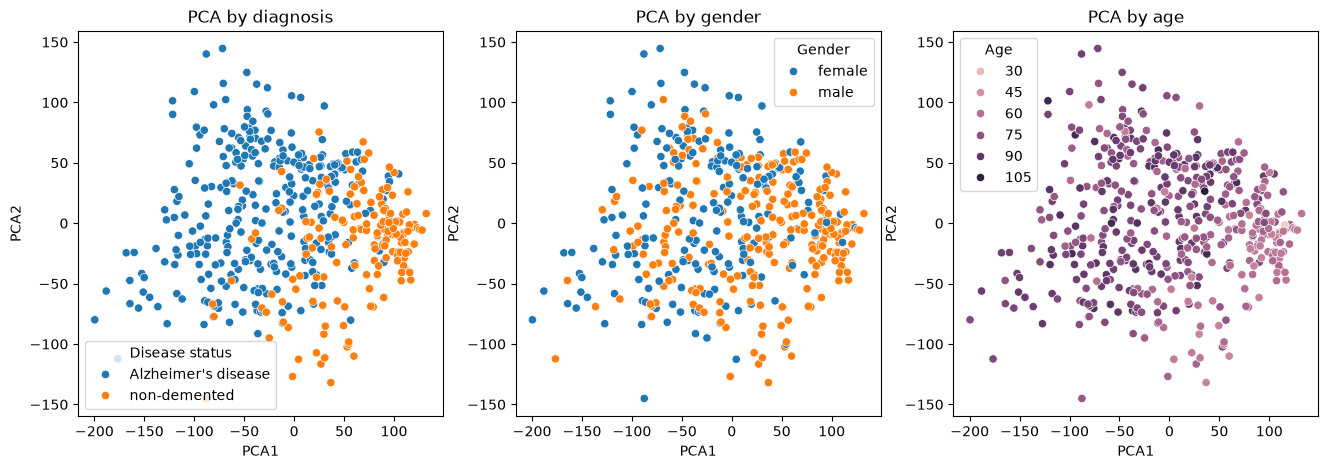

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots( 1, 3, figsize=(16, 5))

sns.scatterplot(df_pca, x='PCA1', y='PCA2', hue='disease_status_ch2', ax=axes[0])
sns.scatterplot(df_pca, x='PCA1', y='PCA2', hue='gender_ch2', ax=axes[1])
sns.scatterplot(df_pca, x='PCA1', y='PCA2', hue='age_ch2', ax=axes[2])

axes[0].set_title('PCA by diagnosis')
axes[1].set_title('PCA by gender')
axes[2].set_title('PCA by age')

axes[0].legend(title='Disease status')
axes[1].legend(title='Gender')
axes[2].legend(title='Age')

fig.figure.savefig('../figures/pca_per_diagnosis_gender_age.png')

plt.show()

In [15]:
# Convert gender to number
df_pca['gender_num_ch2'] = df_pca['gender_ch2'].apply(lambda x: 1 if x == 'female' else 0)
df_pca['disease_status_num_ch2'] = df_pca['disease_status_ch2'].apply(lambda x: 1 if x == 'Alzheimer\'s disease' else 0)

In [16]:
group_pca = ['PCA1', 'PCA2', 'PCA3', 'PCA4', 'PCA5']
group_info = ['disease_status_num_ch2', 'age_ch2', 'gender_num_ch2']
corr = df_pca[group_pca + group_info].corr().abs().loc[group_pca, group_info]

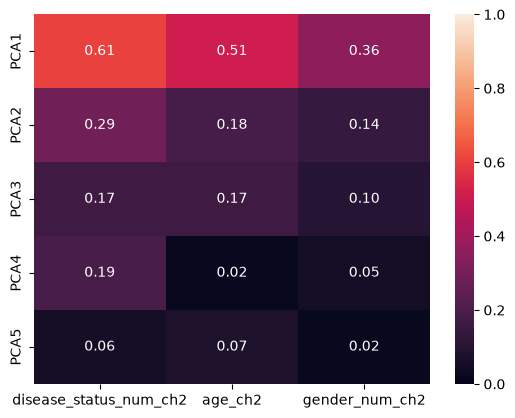

In [17]:
ax = sns.heatmap(corr, annot=True, fmt='.2f', vmin=0, vmax=1)

ax.figure.savefig('../figures/pca_correlation.png')

plt.show()